# Day 6 – RetailMind AI: CNN Image Classification

This notebook implements the Day 6 computer-vision increment in two stages:

1. **Fashion-MNIST prototype** – train and evaluate a CNN on the built-in Keras dataset.
2. **Fashion Product Images** – load real catalogue images, preprocess and augment them, train a CNN, evaluate it, and save the model for reuse in `src/image_classifier.py`.

**Libraries:** TensorFlow / Keras, NumPy, Pandas, Matplotlib, and scikit-learn.

Run the cells from top to bottom. The real-product section expects the Kaggle *Fashion Product Images (Small)* dataset to be extracted under `data/fashion-product-images-small/` with an `images/` folder and `styles.csv` file. You can skip Part B until the dataset is available.

## 1. Install dependencies

Run this once in your environment if the libraries are not installed.

In [1]:
%pip install -q tensorflow pandas numpy matplotlib scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and reproducibility

In [2]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Available GPUs: []


# Part A – Fashion-MNIST prototype

Fashion-MNIST contains 28×28 grayscale images from 10 clothing classes. We use it to validate the CNN architecture before training on real catalogue images.

## 3. Load Fashion-MNIST

In [3]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 6us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 4. Visualize sample images

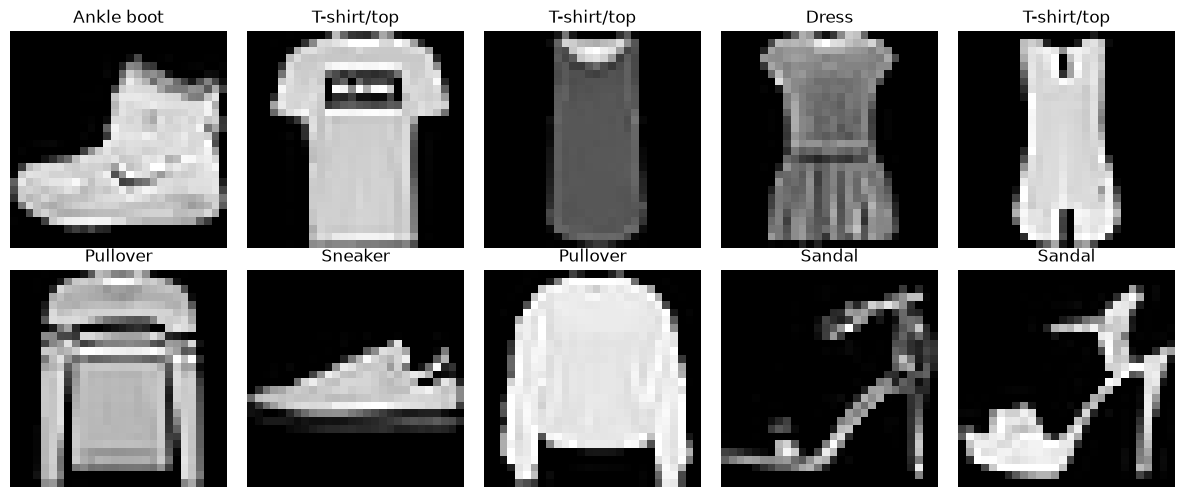

In [4]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Normalize and reshape images

Pixel values are divided by 255 so they are in the range 0–1. CNN input has shape `(height, width, channels)`.

In [5]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (60000, 28, 28, 1)
X_test: (10000, 28, 28, 1)


## 6. Build the Fashion-MNIST CNN

`Conv2D` learns image features, `MaxPooling2D` reduces spatial size, `Dropout` helps reduce overfitting, and `Softmax` returns probabilities for the 10 classes.

In [6]:
fashion_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

fashion_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Compile and train the Fashion-MNIST CNN

In [7]:
fashion_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fashion_history = fashion_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.8045 - loss: 0.5336 - val_accuracy: 0.8694 - val_loss: 0.3703
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.8695 - loss: 0.3622 - val_accuracy: 0.8807 - val_loss: 0.3265
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.8841 - loss: 0.3149 - val_accuracy: 0.8937 - val_loss: 0.2937
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.8972 - loss: 0.2822 - val_accuracy: 0.8963 - val_loss: 0.2904
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.9025 - loss: 0.2615 - val_accuracy: 0.8997 - val_loss: 0.2756
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.9093 - loss: 0.2438 - val_accuracy: 0.9054 - val_loss: 0.2592
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.9150 - loss: 0.2279 - val_accuracy: 0.9034 - val_loss: 0.2678
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.9192 - loss: 0.2146 - 

## 8. Evaluate the Fashion-MNIST model

In [8]:
fashion_test_loss, fashion_test_accuracy = fashion_model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test loss: {fashion_test_loss:.4f}")
print(f"Test accuracy: {fashion_test_accuracy:.4f}")

Test loss: 0.2639
Test accuracy: 0.9063


## 9. Plot training accuracy and loss

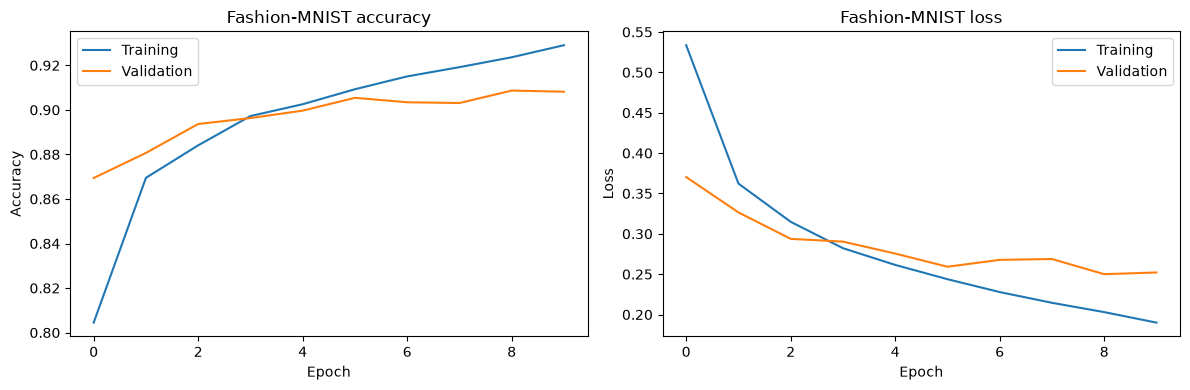

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(fashion_history.history["accuracy"], label="Training")
axes[0].plot(fashion_history.history["val_accuracy"], label="Validation")
axes[0].set_title("Fashion-MNIST accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(fashion_history.history["loss"], label="Training")
axes[1].plot(fashion_history.history["val_loss"], label="Validation")
axes[1].set_title("Fashion-MNIST loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## 10. Confusion matrix and classification report

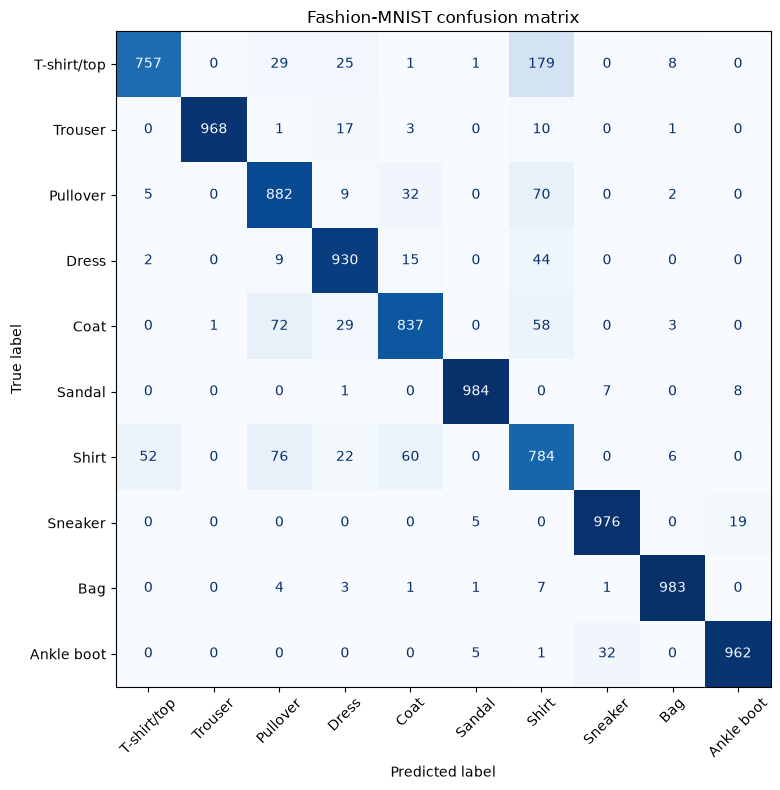

              precision    recall  f1-score   support

 T-shirt/top       0.93      0.76      0.83      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.82      0.88      0.85      1000
       Dress       0.90      0.93      0.91      1000
        Coat       0.88      0.84      0.86      1000
      Sandal       0.99      0.98      0.99      1000
       Shirt       0.68      0.78      0.73      1000
     Sneaker       0.96      0.98      0.97      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



In [10]:
fashion_probabilities = fashion_model.predict(X_test, verbose=0)
fashion_predictions = np.argmax(fashion_probabilities, axis=1)

fashion_cm = confusion_matrix(y_test, fashion_predictions)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=fashion_cm,
    display_labels=class_names
).plot(cmap="Blues", xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title("Fashion-MNIST confusion matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    fashion_predictions,
    target_names=class_names,
    zero_division=0
))

## 11. Predict one Fashion-MNIST image

Predicted class: 4
Predicted name: Coat
Actual name: Coat
Confidence: 99.18%


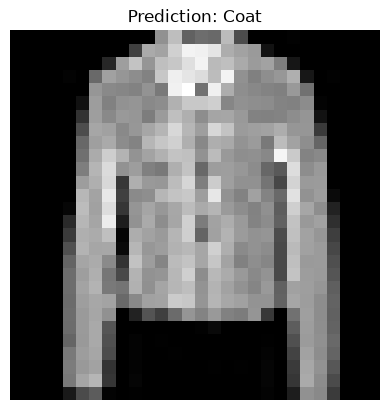

In [11]:
sample_index = 10
sample_image = X_test[sample_index]

sample_probabilities = fashion_model.predict(
    sample_image[np.newaxis, ...],
    verbose=0
)[0]

predicted_index = int(np.argmax(sample_probabilities))

print("Predicted class:", predicted_index)
print("Predicted name:", class_names[predicted_index])
print("Actual name:", class_names[int(y_test[sample_index])])
print(f"Confidence: {sample_probabilities[predicted_index] * 100:.2f}%")

plt.imshow(sample_image.squeeze(), cmap="gray")
plt.title(f"Prediction: {class_names[predicted_index]}")
plt.axis("off")
plt.show()

## 12. Save the Fashion-MNIST model

In [12]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

fashion_model_path = MODEL_DIR / "day6_fashion_mnist_cnn.keras"
fashion_model.save(fashion_model_path)

print("Saved:", fashion_model_path.resolve())

Saved: C:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIND_AI\models\day6_fashion_mnist_cnn.keras


# Part B – Real Fashion Product Images

This section uses the Kaggle dataset **Fashion Product Images (Small)** by `paramaggarwal`.

Expected folder structure:

```text
RETAILMIND_AI/
├── data/
│   └── fashion-product-images-small/
│       ├── images/
│       │   ├── 15970.jpg
│       │   └── ...
│       └── styles.csv
├── models/
└── notebooks/
    └── Day_6_CNN_Image_Classification.ipynb
```

Download and extract the dataset manually from Kaggle, or use the Kaggle CLI after configuring your Kaggle API credentials. Do not commit the full image dataset to Git.

## 13. Set paths and verify the dataset

In [ ]:

from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIND_AI"
)

DATA_DIR = PROJECT_ROOT / "myntradataset"

IMAGE_DIR = DATA_DIR / "images"

CSV_PATH = DATA_DIR / "styles.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset folder:", DATA_DIR.exists())
print("Image folder:", IMAGE_DIR.exists())
print("CSV exists:", CSV_PATH.exists())

if IMAGE_DIR.exists() and CSV_PATH.exists():

    print("\nDataset successfully configured!")

    print(
        "Number of images:",
        len(list(IMAGE_DIR.glob("*.jpg")))
    )

else:
    print("\nDataset path is incorrect. Check folder names.")



Project root: C:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIND_AI
Image folder exists: False
CSV exists: False


FileNotFoundError: Dataset not found. Extract Fashion Product Images (Small) so that 'data/fashion-product-images-small/images' and 'styles.csv' exist.

## 14. Load and inspect product metadata

In [ ]:
df = pd.read_csv(CSV_PATH, on_bad_lines="skip")

print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

if "id" not in df.columns or "masterCategory" not in df.columns:
    raise ValueError("Expected 'id' and 'masterCategory' columns in styles.csv.")

print(df["masterCategory"].value_counts(dropna=False))

## 15. Clean metadata and retain rows with existing images

We use `masterCategory` as the prediction target. This is a broad product category rather than a fine-grained article type.

In [ ]:
df = df.dropna(subset=["id", "masterCategory"]).copy()
df["id"] = pd.to_numeric(df["id"], errors="coerce")
df = df.dropna(subset=["id"]).copy()
df["id"] = df["id"].astype("int64")

df["image_path"] = df["id"].map(
    lambda image_id: str(IMAGE_DIR / f"{image_id}.jpg")
)

df = df[df["image_path"].map(os.path.isfile)].copy()
df = df.drop_duplicates(subset=["id"]).reset_index(drop=True)

print("Rows with existing images:", len(df))
print(df["masterCategory"].value_counts())

## 16. Filter rare categories and encode labels

Categories with fewer than 100 images are excluded so that stratified splitting and training are more reliable. If your dataset is smaller, lower `MIN_IMAGES_PER_CLASS`.

In [ ]:
MIN_IMAGES_PER_CLASS = 100

category_counts = df["masterCategory"].value_counts()
valid_categories = category_counts[
    category_counts >= MIN_IMAGES_PER_CLASS
].index

df = df[df["masterCategory"].isin(valid_categories)].copy()
df = df.reset_index(drop=True)

if df["masterCategory"].nunique() < 2:
    raise ValueError(
        "Fewer than two categories remain. Lower MIN_IMAGES_PER_CLASS "
        "or check that the dataset was extracted correctly."
    )

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["masterCategory"])

class_names_real = label_encoder.classes_.tolist()
NUM_CLASSES = len(class_names_real)

print("Number of classes:", NUM_CLASSES)
print("Class names:", class_names_real)
display(df["masterCategory"].value_counts().to_frame("image_count"))

## 17. Split into train, validation, and test sets

The split is 70% training, 15% validation, and 15% testing. Stratification keeps class proportions similar in each split.

In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

## 18. Create image-loading pipeline

Images are decoded as RGB, resized to 128×128, and normalized to 0–1. Invalid or corrupt image files can cause a decoding error; remove those files or rows if encountered.

In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_product_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def create_product_dataset(dataframe, training=False):
    paths = dataframe["image_path"].astype(str).values
    labels = dataframe["label"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_product_image,
        num_parallel_calls=AUTOTUNE
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset

train_dataset = create_product_dataset(train_df, training=True)
val_dataset = create_product_dataset(val_df)
test_dataset = create_product_dataset(test_df)

print("Image datasets created.")

## 19. Visualize real product images

In [ ]:
images_batch, labels_batch = next(iter(train_dataset))

plt.figure(figsize=(12, 8))
for i in range(min(9, len(images_batch))):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images_batch[i].numpy())
    plt.title(class_names_real[int(labels_batch[i].numpy())])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 20. Build the product CNN with augmentation

Augmentation is applied only during training. It generates small image variations to help the model generalize. The final Dense layer has one output per retained category.

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
], name="data_augmentation")

product_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
], name="retailmind_product_cnn")

product_model.summary()

## 21. Compile and train the product CNN

In [ ]:
product_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

product_history = product_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    callbacks=[early_stopping],
    verbose=1
)

## 22. Evaluate on the held-out test set

In [ ]:
product_test_loss, product_test_accuracy = product_model.evaluate(
    test_dataset,
    verbose=1
)

print(f"Product CNN test loss: {product_test_loss:.4f}")
print(f"Product CNN test accuracy: {product_test_accuracy:.4f}")
print(f"Product CNN test accuracy: {product_test_accuracy * 100:.2f}%")

## 23. Plot product CNN training history

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(product_history.history["accuracy"], label="Training")
axes[0].plot(product_history.history["val_accuracy"], label="Validation")
axes[0].set_title("Product CNN accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(product_history.history["loss"], label="Training")
axes[1].plot(product_history.history["val_loss"], label="Validation")
axes[1].set_title("Product CNN loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## 24. Confusion matrix and classification report

In [ ]:
y_true = []
y_pred = []

for batch_images, batch_labels in test_dataset:
    batch_probabilities = product_model.predict(batch_images, verbose=0)
    batch_predictions = np.argmax(batch_probabilities, axis=1)

    y_true.extend(batch_labels.numpy().tolist())
    y_pred.extend(batch_predictions.tolist())

product_cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(12, 9))
ConfusionMatrixDisplay(
    confusion_matrix=product_cm,
    display_labels=class_names_real
).plot(
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
    colorbar=False
)
ax.set_title("RetailMind product CNN confusion matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names_real,
    zero_division=0
))

## 25. Predict a single product image

In [ ]:
def predict_product(image_path):
    image_path = str(image_path)

    image = tf.keras.utils.load_img(
        image_path,
        target_size=(IMG_SIZE, IMG_SIZE),
        color_mode="rgb"
    )
    image_array = tf.keras.utils.img_to_array(image).astype("float32") / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = product_model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    result = {
        "category": class_names_real[predicted_index],
        "confidence": round(float(probabilities[predicted_index]) * 100, 2)
    }

    print("Predicted category:", result["category"])
    print("Confidence:", f'{result["confidence"]:.2f}%')

    plt.imshow(image)
    plt.title(f'{result["category"]} ({result["confidence"]:.2f}%)')
    plt.axis("off")
    plt.show()

    return result

sample_image_path = test_df.iloc[0]["image_path"]
sample_result = predict_product(sample_image_path)
sample_result

## 26. Save the product model, class names, and evaluation metrics

In [ ]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)

product_model_path = MODEL_DIR / "day6_product_cnn.keras"
class_names_path = MODEL_DIR / "day6_class_names.json"
metrics_path = MODEL_DIR / "day6_cnn_metrics.json"

product_model.save(product_model_path)

with open(class_names_path, "w", encoding="utf-8") as file:
    json.dump(class_names_real, file, indent=4)

day6_metrics = {
    "fashion_mnist_test_accuracy": float(fashion_test_accuracy),
    "fashion_product_test_accuracy": float(product_test_accuracy),
    "fashion_product_test_loss": float(product_test_loss),
    "fashion_product_classes": class_names_real,
    "image_size": IMG_SIZE
}

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(day6_metrics, file, indent=4)

print("Saved model:", product_model_path.resolve())
print("Saved class names:", class_names_path.resolve())
print("Saved metrics:", metrics_path.resolve())

## 27. Reload the saved model and verify prediction

In [ ]:
loaded_product_model = tf.keras.models.load_model(product_model_path)

with open(class_names_path, "r", encoding="utf-8") as file:
    loaded_class_names = json.load(file)

image = tf.keras.utils.load_img(
    sample_image_path,
    target_size=(IMG_SIZE, IMG_SIZE)
)
image_array = tf.keras.utils.img_to_array(image).astype("float32") / 255.0
image_array = np.expand_dims(image_array, axis=0)

loaded_probabilities = loaded_product_model.predict(image_array, verbose=0)[0]
loaded_index = int(np.argmax(loaded_probabilities))

print("Reloaded model prediction:", loaded_class_names[loaded_index])
print("Confidence:", f"{loaded_probabilities[loaded_index] * 100:.2f}%")

# Part C – Reusable module for the RetailMind application

Create the following file at `src/image_classifier.py`. This is the reusable inference module; it loads the saved model and predicts a category without retraining.

```python
import json
import numpy as np
import tensorflow as tf
from pathlib import Path


BASE_DIR = Path(__file__).resolve().parent.parent
MODEL_PATH = BASE_DIR / "models" / "day6_product_cnn.keras"
LABEL_PATH = BASE_DIR / "models" / "day6_class_names.json"
IMG_SIZE = 128


class ProductImageClassifier:
    def __init__(self):
        self.model = tf.keras.models.load_model(MODEL_PATH)
        with open(LABEL_PATH, "r", encoding="utf-8") as file:
            self.class_names = json.load(file)

    def predict(self, image_path):
        image = tf.keras.utils.load_img(
            image_path,
            target_size=(IMG_SIZE, IMG_SIZE),
            color_mode="rgb"
        )
        image = tf.keras.utils.img_to_array(image).astype("float32") / 255.0
        image = np.expand_dims(image, axis=0)

        probabilities = self.model.predict(image, verbose=0)[0]
        index = int(np.argmax(probabilities))

        return {
            "category": self.class_names[index],
            "confidence": round(float(probabilities[index]) * 100, 2)
        }
```

Test it from the project root:

```python
from src.image_classifier import ProductImageClassifier

classifier = ProductImageClassifier()
result = classifier.predict("data/test_product.jpg")
print(result)
```

# Part D – Day 6 completion checklist

- [ ] Fashion-MNIST CNN trained and evaluated.
- [ ] Fashion-MNIST confusion matrix generated.
- [ ] Real Fashion Product Images dataset downloaded and extracted.
- [ ] Product metadata cleaned and labels encoded.
- [ ] Train, validation, and test sets created.
- [ ] Image preprocessing and augmentation implemented.
- [ ] Product CNN trained and evaluated.
- [ ] Product confusion matrix and classification report generated.
- [ ] Product model and class-name mapping saved.
- [ ] `src/image_classifier.py` created and tested.
- [ ] README updated with actual measured accuracies.

**Important:** Do not put invented accuracy values in the README. Copy the actual values printed by the evaluation cells. Fashion-MNIST and the real product dataset are separate experiments; the real product CNN is the model intended for the RetailMind catalogue classifier.